# Airbnb in Rio de Janeiro: regression and classification

A practice project for **course 1 of the [Machine Learning Specialization](https://www.coursera.org/specializations/machine-learning-introduction)**: linear regression, the cost function, gradient descent, feature scaling, polynomial features, overfitting, regularization and logistic regression, practised with scikit-learn on real data.

Two questions about **43,192 Airbnb listings in Rio**:
1. **What drives the nightly price?** (linear regression)
2. **Can you tell a business host from someone renting their own place?** (logistic regression)

Each step below starts with the decision made at that point, then the code and the result.

**Data:**
- **Listings:** [Inside Airbnb](https://insideairbnb.com/), Rio de Janeiro snapshot of 22 September 2026 (CC BY 4.0).
- **Beaches and metro stations:** © [OpenStreetMap](https://www.openstreetmap.org/copyright) contributors (ODbL).

All the logic is in [`src/rio.py`](../src/rio.py) (data and features) and [`src/lesson.py`](../src/lesson.py) (the lessons).

In [1]:
import json, sys
sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
import lesson
from rio import DATA, load_listings, split_by_host

d = load_listings()
d['split'] = split_by_host(d)
tr, va, te = (d[d.split == s] for s in ('train', 'validation', 'test'))
show = lambda name: display(Image(filename=f'../figures/{name}', width=1000))
print(f'{len(d):,} listings: {len(tr):,} train, {len(va):,} validation, {len(te):,} test')

43,192 listings: 29,970 train, 6,876 validation, 6,346 test


## 1. The data, and the decisions behind it

- **Price on a log scale.** Prices run from about R$90 to R$7,500 a night. Predicting the log of the price means the model learns a **base price** and **multipliers** ("a sea view adds X%"), which suits prices this lopsided. Missing prices and the extreme 1% at either end are dropped.
- **A business host runs 3 or more listings**: anyone using Airbnb as a source of income, not necessarily a company. That's 43% of listings. The host's listing counts are the answer, so they are never used as features.
- **Features:**
  - **Location:** distance to the nearest ocean beach, distance to the nearest bay beach, distance to the metro, neighbourhood, sea view, beachfront.
  - **The place:** room type, guests, bedrooms, bathrooms, shared bath.
  - **Reviews:** rating, years on Airbnb (from the first review), number of reviews.
  - Building age isn't in the data.
- **Ocean or bay beaches?** Both are kept, to test whether Guanabara Bay beaches like Botafogo's matter, or only the ocean.
- **Split:** 70% train, 15% validation (for choices), 15% test (used once, at the end). **Every host's listings stay on the same side**: otherwise a big host's other flats in training would give away its listings in the test.

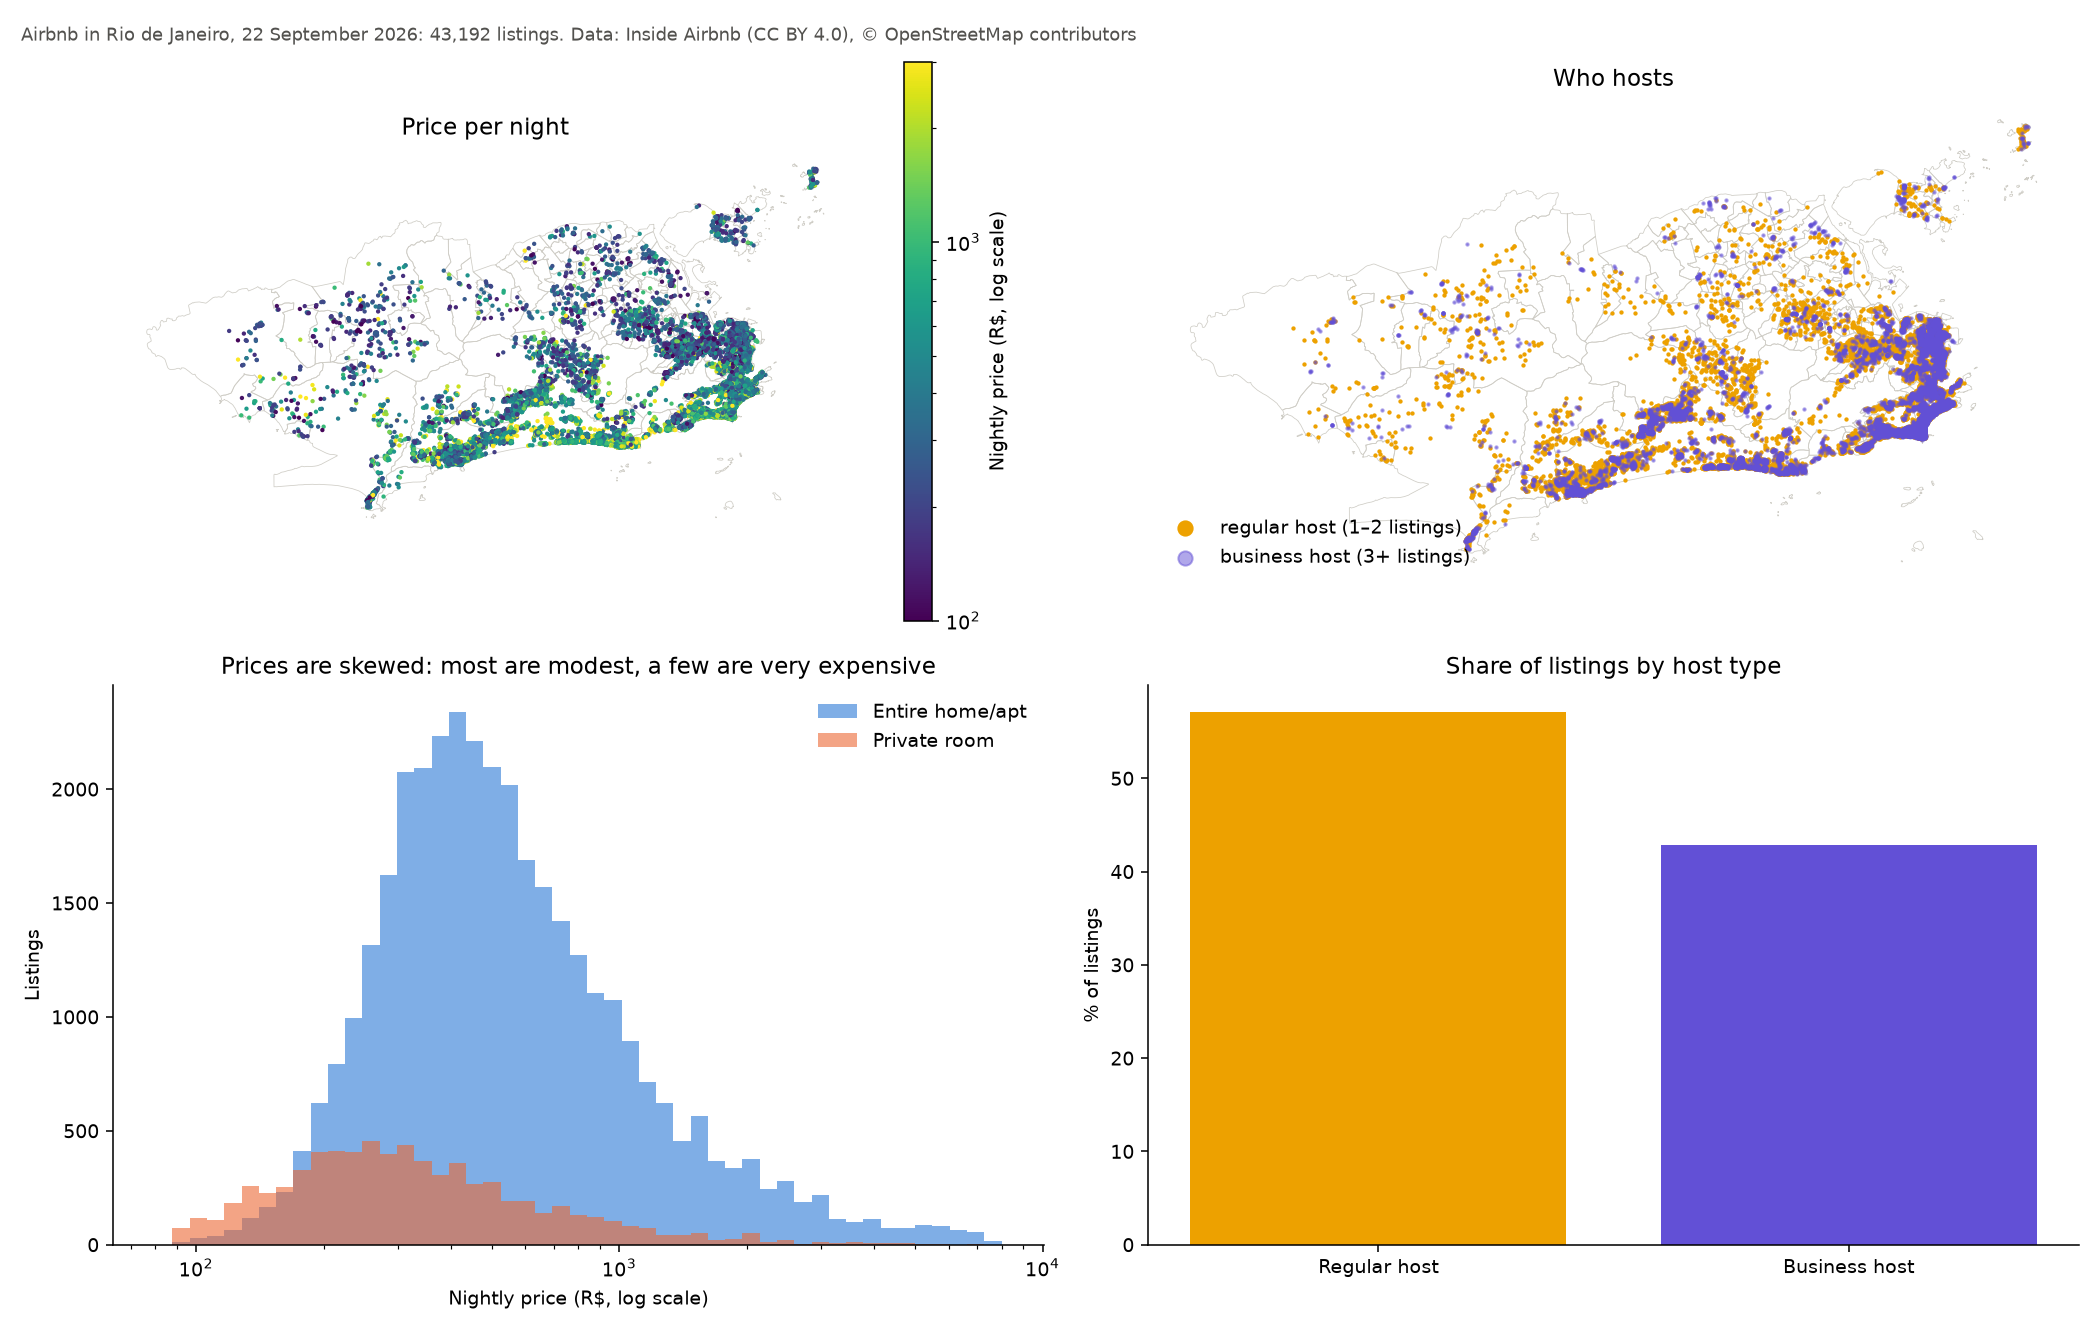

In [2]:
lesson.explore(d, DATA / 'neighbourhoods.geojson', save='01_explore.png'); show('01_explore.png')

**Ocean vs bay beaches.** Price falls steadily with distance from an **ocean** beach, while distance to a **bay** beach shows no pattern. Botafogo, near a bay beach, sits right on the ocean curve: its premium over areas like Tijuca comes from being about 2 km from Copacabana, not from its own beach.

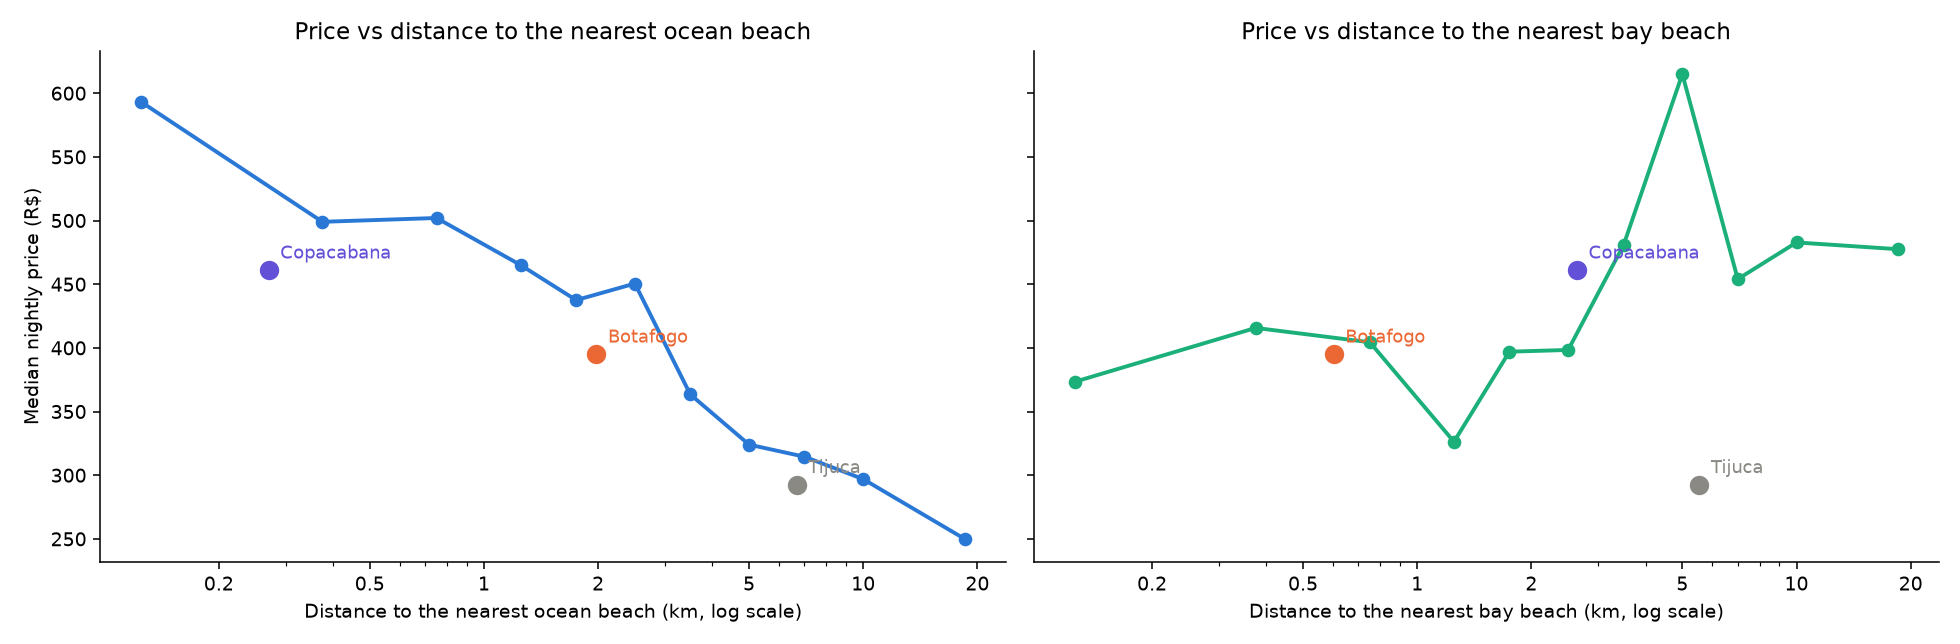

,neighbourhood,median price (R$),km to ocean beach,km to bay beach,km to metro
0,Ipanema,752,0.3,4.5,0.38
1,Copacabana,461,0.3,2.6,0.47
2,Botafogo,395,2.0,0.6,0.59
3,Tijuca,292,6.7,5.5,0.45
4,Centro,289,5.2,2.0,0.39


In [3]:
lesson.beaches(tr, save='02_beaches.png'); show('02_beaches.png')
pd.DataFrame([{'neighbourhood': n, 'median price (R$)': round(g.price.median()),
               'km to ocean beach': round(g.km_ocean_beach.median(), 1), 'km to bay beach': round(g.km_bay_beach.median(), 1),
               'km to metro': round(g.km_metro.median(), 2)}
              for n in ['Ipanema', 'Copacabana', 'Botafogo', 'Tijuca', 'Centro'] for g in [tr[tr.neighbourhood == n]]])

## 2. Baselines: the simplest guesses to beat

Guess: does **location** or **size** matter more? Each baseline predicts the typical price of similar listings in the training set.

**Typical miss** is how far off a typical prediction is (60% means about 1.6 times too high or too low). **R²** is the share of price variation explained.

In [4]:
base = lesson.baselines(tr, va)
pd.DataFrame({k: v for k, v in base.items() if isinstance(v, dict)}).T

,r2,typical_miss_pct,median_miss_brl
typical Rio price,-0.020,77.3,185.0
location only (neighbourhood),0.132,67.0,157.0
size only (room type x bedrooms),0.336,57.9,150.0
both,0.329,55.3,133.0


**Size beats location** in a simple lookup. Within one neighbourhood, prices vary enormously (Copacabana alone has about 15,000 listings), while "a whole three-bedroom flat" narrows things down a lot. For the business question, always guessing "not business" sets the accuracy bar.

## 3. Gradient descent, one feature

Chosen feature: **bedrooms**. scikit-learn's `SGDRegressor` *is* gradient descent. Calling `partial_fit` once per pass lets us record the cost (the average squared miss) after each pass, for three learning rates.

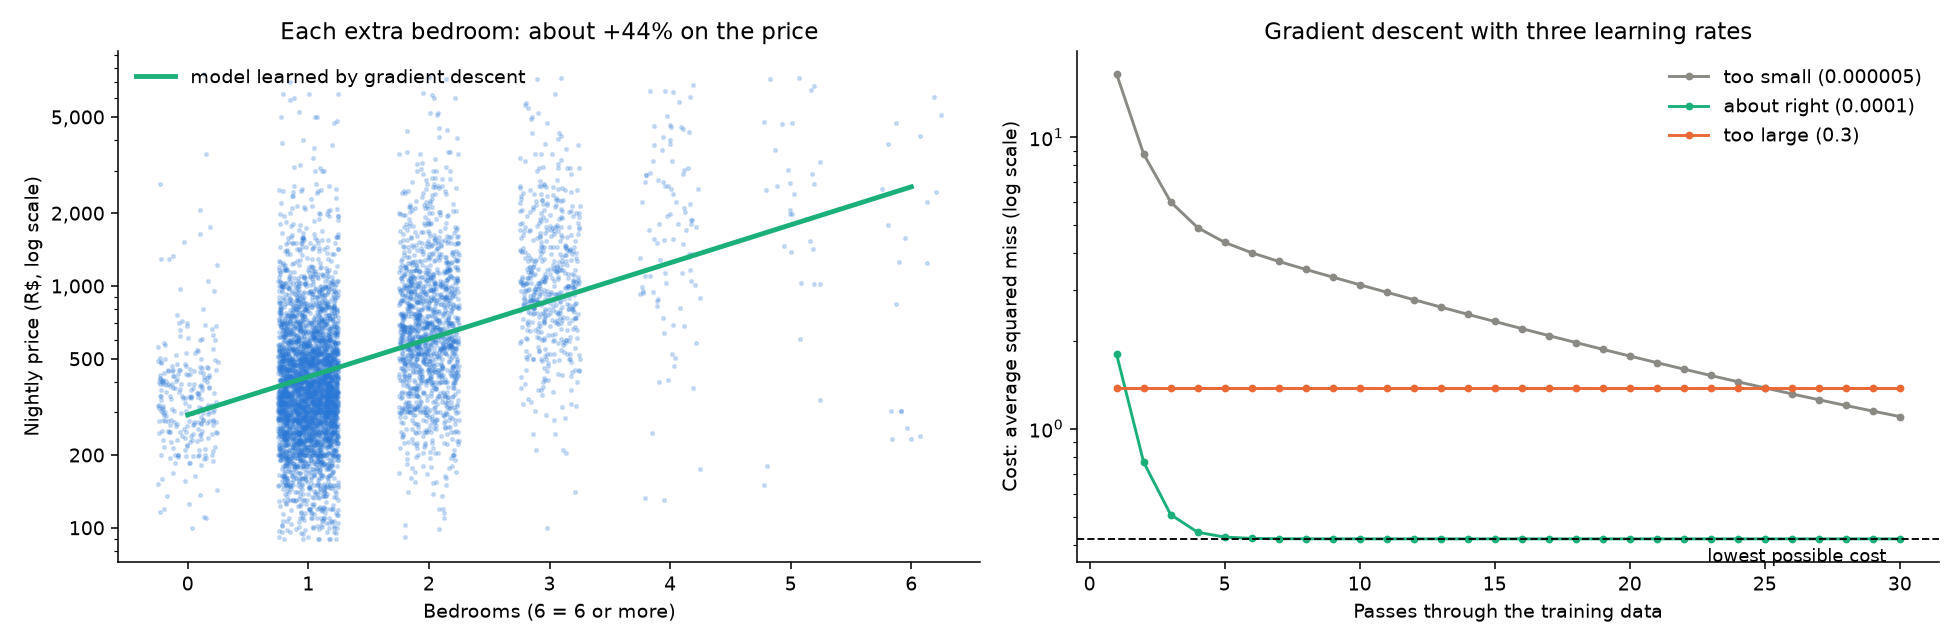

{'base_price_brl': 293,
 'per_bedroom_pct': 43.6,
 'validation': {'r2': 0.262, 'typical_miss_pct': 62.2, 'median_miss_brl': 171}}

In [5]:
one = lesson.gradient_descent_one_feature(tr, va, save='03_gradient_descent.png'); show('03_gradient_descent.png'); one

- **Base price** for a studio, **multiplied** for each extra bedroom: that's the log-price idea at work. The line is straight on a log scale, so each bedroom adds the same *percentage*.
- **Learning rate:**
  - *about right* reaches the lowest possible cost in a few passes;
  - *too small* crawls;
  - *too large* overshoots and bounces, and even larger rates explode.

## 4. All the features, and feature scaling

Features run on very different scales: bedrooms from 0 to 10, distances from 0 to 40 km, reviews up to about 800. Prediction made beforehand: without scaling, gradient descent gets **bouncier**.

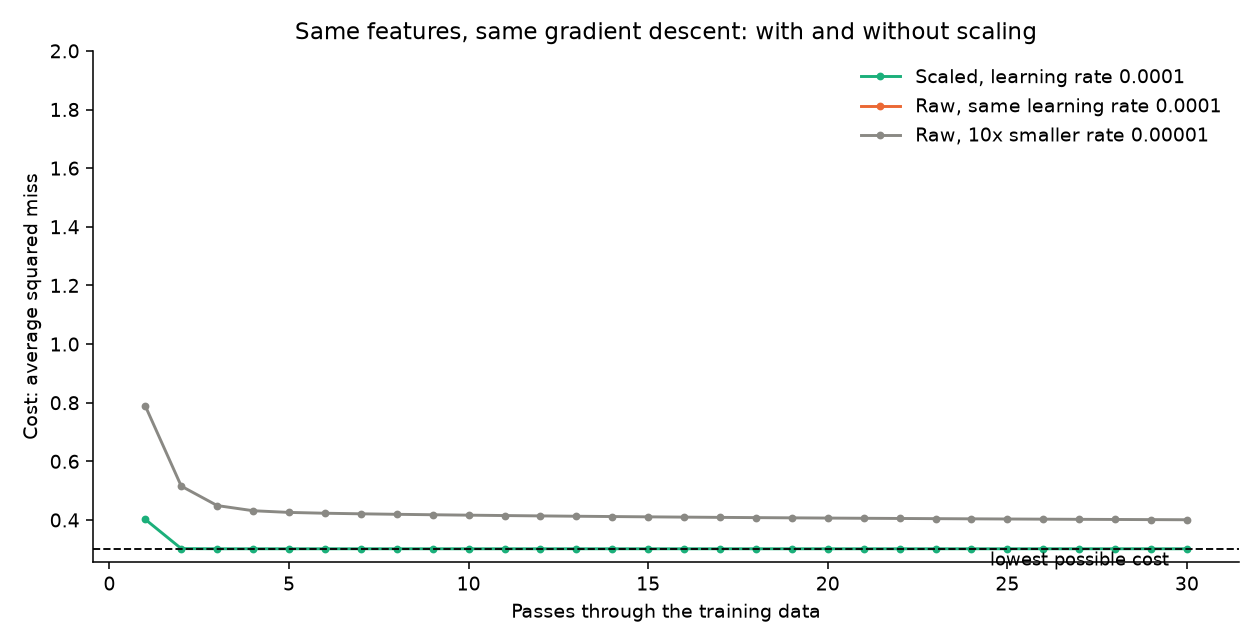

final cost after 30 passes: {'Scaled, learning rate 0.0001': 0.302, 'Raw, same learning rate 0.0001': 134.92, 'Raw, 10x smaller rate 0.00001': 0.401} | lowest possible: 0.302
validation: {'r2': 0.463, 'typical_miss_pct': 51.3, 'median_miss_brl': 142}


,% change in price per unit
km_ocean_beach,-4.9
km_bay_beach,1.0
km_metro,-1.8
sea_view,20.6
beachfront,7.8
guests,6.4
bedrooms,16.3
bathrooms,12.3
shared_bath,-23.9
rating,11.5


In [6]:
allf = lesson.scaling_and_features(tr, va, save='04_scaling.png'); show('04_scaling.png')
print('final cost after 30 passes:', allf['scaling_final_cost'], '| lowest possible:', allf['lowest_cost'])
print('validation:', allf['validation'])
pd.Series(allf['effects_pct'], name='% change in price per unit').to_frame()

- **Scaling:**
  - Raw features at the scaled run's learning rate bounce *away* from the answer.
  - A 10× smaller rate is stable but slow.
  - Scaled features converge in two passes.
- **Each feature's effect, holding the others fixed:**
  - Distance to the ocean is the most important single feature, at about −5% per km.
  - Sea view adds about +21%; the metro about −2% per km away.
  - The bay beach *doesn't* add a premium.
- **Bedrooms drop from about +44% to about +16%** once guests and bathrooms are in the model: overlapping features share the effect.
- **Listings with no reviews yet ask more**, and more reviews go with lower prices.

## 5. Curves, overfitting and regularization

Prediction made beforehand: adding all 151 neighbourhoods would *hurt* on new listings. Then the model gets more flexible with polynomial features (curves and combinations), and Ridge pulls it back.

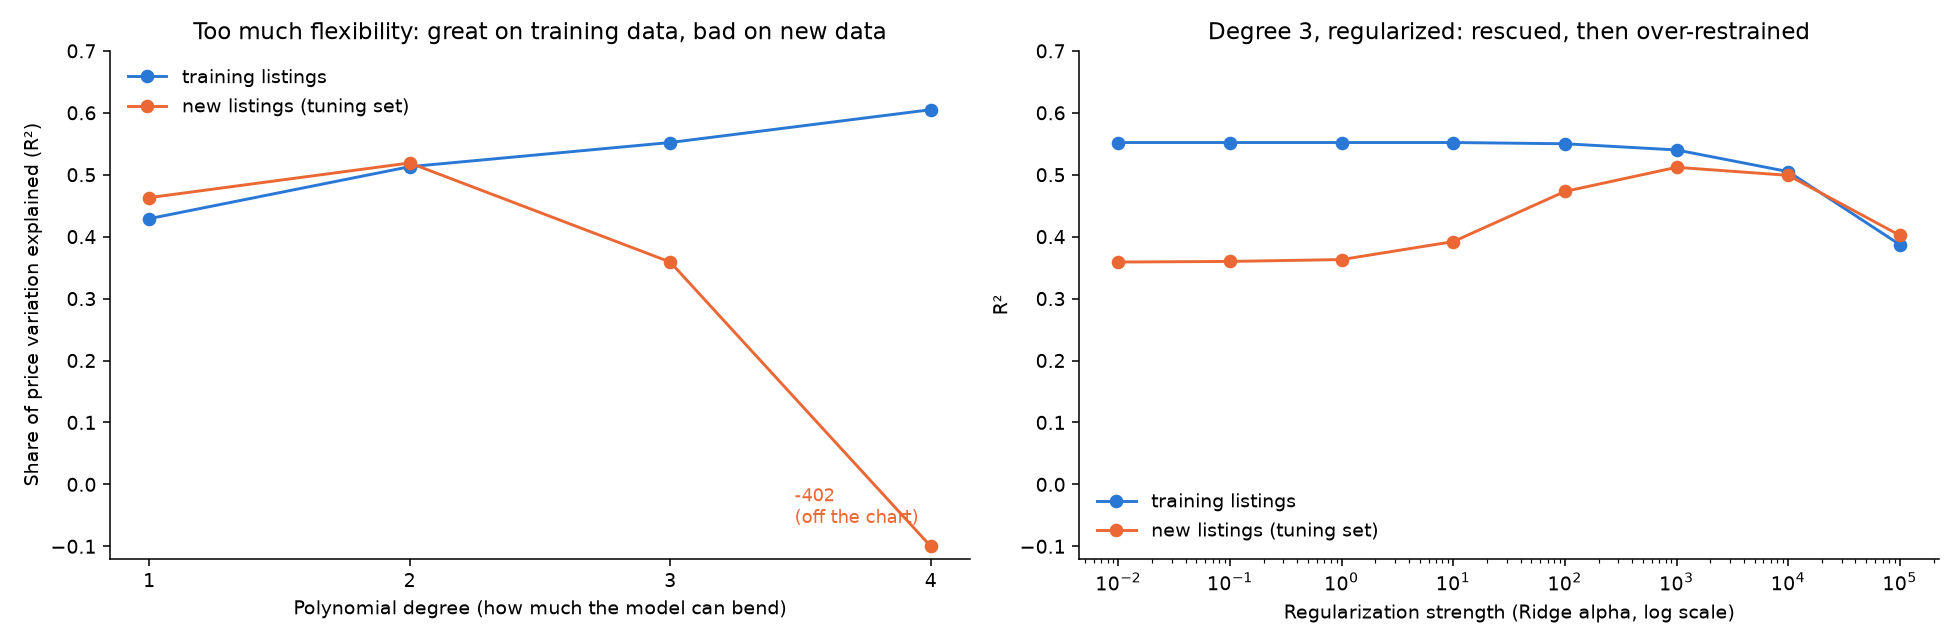

with neighbourhoods: {'train_r2': 0.492, 'val_r2': 0.506}


,degree,terms,train_r2,val_r2
0,1,15,0.429,0.463
1,2,135,0.513,0.519
2,3,815,0.552,0.359
3,4,3875,0.605,-401.696


,alpha,r2,typical_miss_pct,median_miss_brl
0,1,0.538,46.0,128
1,10,0.538,46.0,128
2,100,0.539,46.0,128
3,1000,0.539,46.1,127
4,10000,0.519,47.6,131


In [7]:
over = lesson.overfitting(tr, va, save='05_overfitting.png'); show('05_overfitting.png')
print('with neighbourhoods:', over['with_neighbourhoods'])
display(pd.DataFrame(over['degrees']))
pd.DataFrame([{'alpha': r['alpha'], **r['val']} for r in over['best_model_alphas']])

- **Neighbourhoods helped** on new listings. Rare ones (fewer than 10 listings) are grouped together so the model can't memorise them.
- **Degree 2 helps; degrees 3 and 4 overfit:** better on training data, much worse on new listings (degree 4 is far worse than guessing the average).
- **Ridge** (one penalty on all the weights, after scaling so the penalty is even) rescues degree 3. Too much regularization makes it worse again.
- **Best price model:** degree 2 curves, plus neighbourhoods, plus light Ridge. It explains about 54% of price variation on new listings. The rest is what the data can't see: photos, decor, pricing strategy.

## 6. Business host or not? Logistic regression

Booking behaviour is added (days available, minimum nights, instant booking, superhost). The host's response and acceptance rates are empty in this snapshot.

Decision: a **false alarm** (calling someone who rents their own flat a business) is worse than missing a business, so the cut-off is set high, at **0.7**.

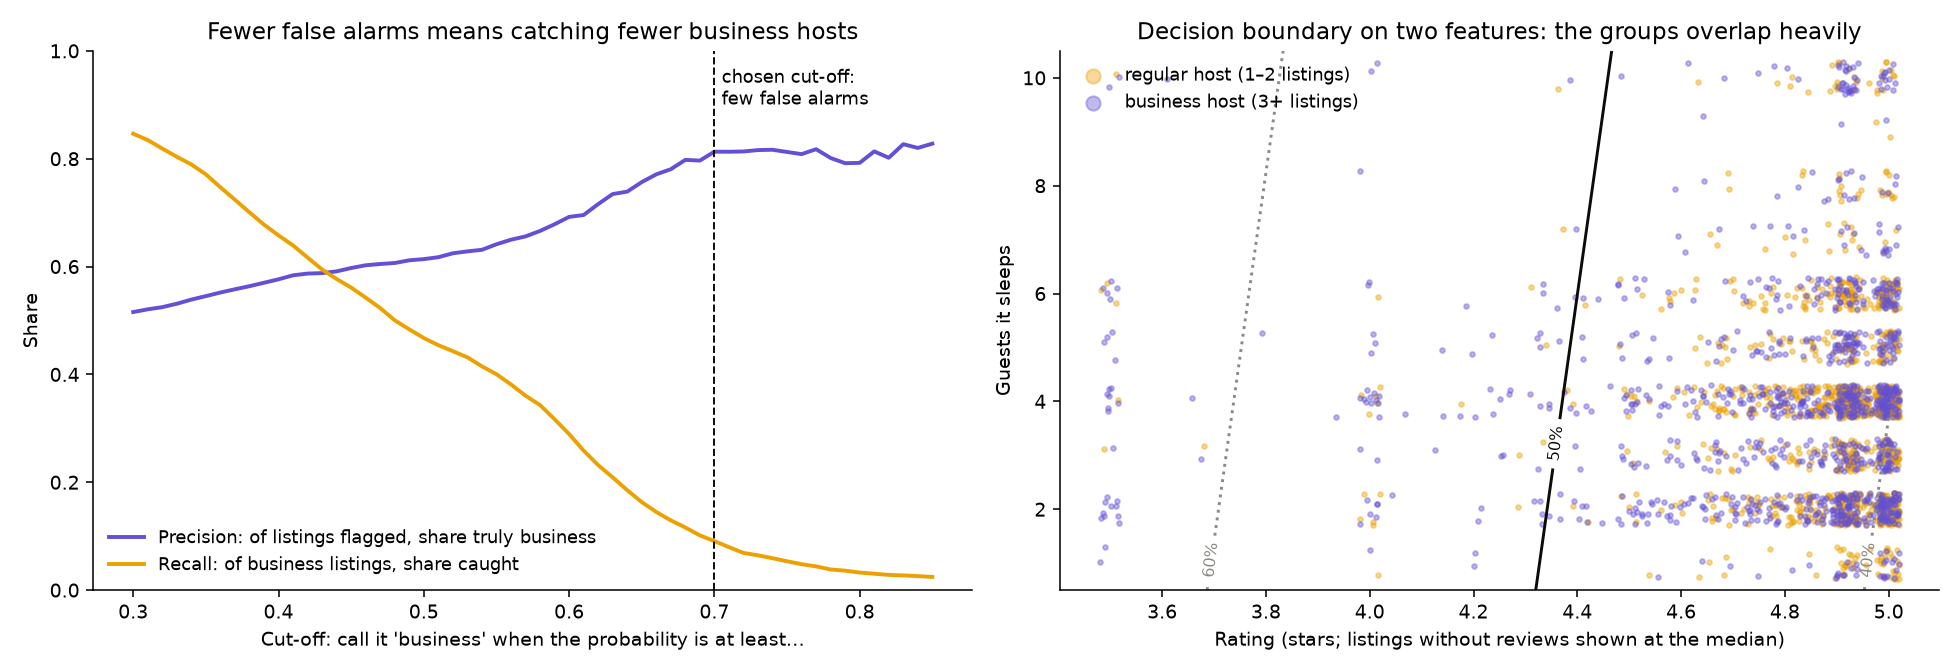

{'price features': 0.607, '+ booking behaviour': 0.668} | strongest signs: {'superhost': 0.49, 'rating': -0.28, 'room_shared': 0.17, 'room_private': 0.17, 'km_ocean_beach': -0.17, 'bedrooms': -0.16}


,threshold,accuracy,flagged_pct,precision,recall
0,0.5,0.620,35.0,0.614,0.467
1,0.6,0.614,19.2,0.692,0.289
2,0.7,0.572,5.1,0.813,0.091
3,0.8,0.551,1.9,0.792,0.033


In [8]:
cls = lesson.classification(tr, va, threshold=0.7, save='06_classification.png'); show('06_classification.png')
print({k: cls[k]['auc'] for k in ['price features', '+ booking behaviour']}, '| strongest signs:', cls['strongest_signs'])
pd.DataFrame(cls['thresholds'])

- **The honest finding: you can't reliably tell a business host from a listing alone.**
  - The strongest sign is superhost status; lower ratings and newer listings lean business.
  - The two groups overlap heavily, as the decision boundary shows.
- **The threshold is a business decision:**
  - raising it makes flags more often right (precision);
  - but it catches fewer business hosts (recall).

## 7. Final test, once

The test set was never used for any choice above.

In [9]:
res = json.load(open('../reports/results.json'))
res['test']

{'price_model': {'alpha': 100,
  'r2': 0.542,
  'typical_miss_pct': 44.9,
  'median_miss_brl': 123},
 'price_baseline_both_lookup': {'r2': 0.361,
  'typical_miss_pct': 54.0,
  'median_miss_brl': 134},
 'business': {'auc': 0.641,
  'always_not_business_accuracy': 0.587,
  'at_0.5': {'threshold': 0.5,
   'accuracy': 0.598,
   'flagged_pct': 30.3,
   'precision': 0.519,
   'recall': 0.381},
  'at_chosen': {'threshold': 0.7,
   'accuracy': 0.597,
   'flagged_pct': 3.0,
   'precision': 0.668,
   'recall': 0.049}}}

## What I learned

- **Simple baselines first:** a lookup by size beats one by neighbourhood, and every model has to beat both.
- **Learning rate and scaling go together:** without scaling, a rate that suits one feature makes another bounce.
- **Coefficients depend on what else is in the model:** bedrooms "worth" +44% alone, about +16% next to guests and bathrooms.
- **More flexibility isn't more accuracy.** The tuning set, not the training set, says when to stop, and regularization pulls an over-flexible model back.
- **A classifier gives a trade-off, not an answer:** choosing the threshold means choosing which mistake costs more.